# 04 · Non-linear models: SVR and Gaussian process
Tests two non-linear models for SOH against Ridge (linear reference)

In [4]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from src import evaluation as ev

df = ev.load_labelled()
numeric, categorical = ev.main_features()
print(df.shape, len(numeric), categorical)

(306, 76) 42 ['schedule']


## 1. Models and settings tried
- **SVR (RBF):** fits a smooth curve and ignores small errors inside a margin (epsilon). Tried C ∈ {1, 10, 30, 100, 300}, gamma ∈ {scale, 0.003, 0.01, 0.03, 0.1}, epsilon ∈ {0.1, 0.5, 1.0}.
- **Gaussian process (GP):** also fits a smooth curve, and gives an uncertainty for each prediction. Tried 3 kernels: RBF, Matérn 1.5, Matérn 2.5 (each + white noise).
- **Ridge:** linear reference, alpha from 0.001 to 1000 (same grid as the baselines notebook).

In [5]:
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel as C, RBF, Matern, WhiteKernel

# Ridge = linear reference (same grid as the baselines notebook)
ridge = ev.ModelSpec("Ridge", Ridge(), {"alpha": list(np.logspace(-3, 3, 13))}, family="linear")

# SVR with RBF kernel: tune C, gamma, epsilon
svr = ev.ModelSpec(
    "SVR (RBF)", SVR(kernel="rbf"),
    {"C": [1, 10, 30, 100, 300],
     "gamma": ["scale", 0.003, 0.01, 0.03, 0.1],
     "epsilon": [0.1, 0.5, 1.0]},
    family="non-linear")

# Gaussian process: the grid only picks the kernel type
def k_rbf():  return C(1.0, (1e-2, 1e3)) * RBF(5.0, (1e-2, 1e3)) + WhiteKernel(1.0, (1e-5, 1e2))
def k_m15():  return C(1.0, (1e-2, 1e3)) * Matern(5.0, (1e-2, 1e3), nu=1.5) + WhiteKernel(1.0, (1e-5, 1e2))
def k_m25():  return C(1.0, (1e-2, 1e3)) * Matern(5.0, (1e-2, 1e3), nu=2.5) + WhiteKernel(1.0, (1e-5, 1e2))

gpr = ev.ModelSpec(
    "Gaussian process",
    GaussianProcessRegressor(normalize_y=True, n_restarts_optimizer=2, random_state=0),
    {"kernel": [k_rbf(), k_m15(), k_m25()]},
    family="non-linear")

print("Models ready:", ridge.name, "|", svr.name, "|", gpr.name)

Models ready: Ridge | SVR (RBF) | Gaussian process


In [6]:
%%time
results = []
for spec in [ridge, svr, gpr]:
    results.append(ev.run_cv(df, spec, "LOCO"))

R = {(r.model, r.scheme): r for r in results}
display(ev.summary_table(results).round(2))

Ridge | LOCO: fold 15
SVR (RBF) | LOCO: fold 15
Gaussian process | LOCO: fold 15


,model,scheme,n,MAE,RMSE,R2,MaxAE
0,Ridge,LOCO,306,4.76,7.63,0.53,49.88
1,SVR (RBF),LOCO,306,4.81,8.20,0.45,56.38
2,Gaussian process,LOCO,306,7.72,12.77,-0.32,56.06


CPU times: user 54.5 s, sys: 9.77 s, total: 1min 4s
Wall time: 1min 43s


## 3. Error per cell, chosen settings, worst predictions

In [7]:
models = ["Ridge", "SVR (RBF)", "Gaussian process"]

# 1) MAE for each held-out cell, models side by side
folds = pd.concat([R[(m, "LOCO")].folds for m in models])
display(folds.pivot(index="held_out", columns="model", values="MAE")[models].round(2))

# 2) Settings each fold picked
for m in ["SVR (RBF)", "Gaussian process"]:
    print("\n", m)
    display(R[(m, "LOCO")].folds[["held_out", "best_params"]])

# 3) The 10 worst predictions
oof = pd.concat([R[(m, "LOCO")].oof for m in models])
oof["abs_err"] = (oof.y_pred - oof.y_true).abs()
display(oof.sort_values("abs_err", ascending=False)
           [["model", "cell_id", "rtp_index", "y_true", "y_pred", "abs_err", "regime"]].head(10).round(2))

model,Ridge,SVR (RBF),Gaussian process
held_out,,,
2_009,1.90,1.68,1.39
2_010,2.71,2.14,2.42
2_012,7.97,9.74,15.32
2_027,2.33,2.68,3.35
2_030,4.78,4.14,11.77
2_033,7.27,6.33,2.97
2_058,2.30,1.79,1.98
2_067,4.91,6.46,8.36
2_076,10.09,16.17,18.51



 SVR (RBF)


,held_out,best_params
0,2_009,"{'C': 30, 'epsilon': 1.0, 'gamma': 0.003}"
1,2_010,"{'C': 30, 'epsilon': 1.0, 'gamma': 0.003}"
2,2_012,"{'C': 10, 'epsilon': 1.0, 'gamma': 0.003}"
3,2_027,"{'C': 30, 'epsilon': 0.5, 'gamma': 0.003}"
4,2_030,"{'C': 30, 'epsilon': 1.0, 'gamma': 0.003}"
5,2_033,"{'C': 30, 'epsilon': 1.0, 'gamma': 0.003}"
6,2_058,"{'C': 30, 'epsilon': 1.0, 'gamma': 0.003}"
7,2_067,"{'C': 10, 'epsilon': 1.0, 'gamma': 0.003}"
8,2_076,"{'C': 10, 'epsilon': 1.0, 'gamma': 0.01}"
9,2_092,"{'C': 100, 'epsilon': 1.0, 'gamma': 0.003}"



 Gaussian process


,held_out,best_params
0,2_009,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
1,2_010,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
2,2_012,{'kernel': 1**2 * RBF(length_scale=5) + WhiteK...
3,2_027,"{'kernel': 1**2 * Matern(length_scale=5, nu=2...."
4,2_030,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
5,2_033,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
6,2_058,{'kernel': 1**2 * RBF(length_scale=5) + WhiteK...
7,2_067,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
8,2_076,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
9,2_092,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."


,model,cell_id,rtp_index,y_true,y_pred,abs_err,regime
215,SVR (RBF),2_095,15,33.26,89.64,56.38,extrapolation
215,Gaussian process,2_095,15,33.26,89.32,56.06,extrapolation
216,SVR (RBF),2_095,16,38.40,89.49,51.09,extrapolation
216,Gaussian process,2_095,16,38.40,89.04,50.64,extrapolation
215,Ridge,2_095,15,33.26,83.14,49.88,extrapolation
199,Gaussian process,2_092,21,89.95,42.56,47.40,extrapolation
200,Gaussian process,2_092,22,88.20,40.91,47.30,extrapolation
198,Gaussian process,2_092,20,90.32,44.73,45.59,extrapolation
216,Ridge,2_095,16,38.40,83.00,44.59,extrapolation
197,Gaussian process,2_092,19,90.58,46.55,44.03,extrapolation


## 4. Paired comparison and error breakdown
Per-fold MAE on the same 15 folds. Negative mean_diff = model "a" is better; the Wilcoxon p-value says whether the difference is consistent across folds.

In [8]:
# 1) Paired comparison on the same 15 folds
display(pd.DataFrame([
    ev.paired_comparison(R[("SVR (RBF)", "LOCO")],        R[("Ridge", "LOCO")]),
    ev.paired_comparison(R[("Gaussian process", "LOCO")], R[("Ridge", "LOCO")]),
    ev.paired_comparison(R[("Gaussian process", "LOCO")], R[("SVR (RBF)", "LOCO")]),
]).round(3))

# 2) Error by health class and by interpolation vs extrapolation
for m in models:
    oof_m = R[(m, "LOCO")].oof
    print(f"\n===== {m} =====")
    display(ev.breakdown(oof_m, "health_class").round(2))
    display(ev.breakdown(oof_m, "regime").round(2))

,a,b,scheme,n_folds,mean_diff,a_wins,b_wins,wilcoxon_p
0,SVR (RBF),Ridge,LOCO,15,0.391,9,6,0.847
1,Gaussian process,Ridge,LOCO,15,3.213,5,10,0.048
2,Gaussian process,SVR (RBF),LOCO,15,2.822,3,12,0.012



===== Ridge =====


,health_class,n,MAE,RMSE,bias
0,EOL risk (<80),53,10.10,14.03,9.22
1,Degraded (80-90),66,3.69,5.74,-2.35
2,Healthy (>=90),187,3.63,5.27,-1.64


,regime,n,MAE,RMSE,bias
0,extrapolation,66,10.27,13.78,2.14
1,interpolation,219,3.09,3.93,-0.93
2,unclassified,21,4.91,9.50,4.33



===== SVR (RBF) =====


,health_class,n,MAE,RMSE,bias
0,EOL risk (<80),53,13.11,17.59,12.56
1,Degraded (80-90),66,3.30,4.15,-0.68
2,Healthy (>=90),187,2.99,4.04,-1.50


,regime,n,MAE,RMSE,bias
0,extrapolation,66,10.96,15.26,5.20
1,interpolation,219,2.80,3.45,-0.61
2,unclassified,21,6.46,11.16,6.24



===== Gaussian process =====


,health_class,n,MAE,RMSE,bias
0,EOL risk (<80),53,16.37,19.82,15.80
1,Degraded (80-90),66,6.07,10.10,-0.82
2,Healthy (>=90),187,5.85,10.94,-4.10


,regime,n,MAE,RMSE,bias
0,extrapolation,66,20.55,24.93,0.01
1,interpolation,219,3.79,5.13,-0.73
2,unclassified,21,8.36,12.19,8.32


## 5. Gaussian process uncertainty
The GP gives a standard deviation for each prediction. Coverage = how often the true SOH falls inside the 95% band (ideal ≈ 95%). Correlation = does the GP know when it is wrong?

In [9]:
%%time
gp_res = R[("Gaussian process", "LOCO")]
X = df[numeric + categorical + ["cell_id"]]
y = df["SOH"].to_numpy(float)
mu, sd = np.zeros(len(df)), np.zeros(len(df))

for k, (tr, te) in enumerate(ev.outer_folds(df, "LOCO")):
    kern = gp_res.folds.loc[k, "best_params"]["kernel"]
    pipe = ev.make_pipeline(clone(gpr.estimator).set_params(kernel=kern), numeric, categorical)
    pipe.fit(X.iloc[tr], y[tr])
    Z = pipe.named_steps["prep"].transform(X.iloc[te])
    mu[te], sd[te] = pipe.named_steps["model"].predict(Z, return_std=True)

print("MAE check (should match GP LOCO above):", np.abs(mu - y).mean().round(2))

lo, hi = mu - 1.96 * sd, mu + 1.96 * sd
unc = df[["cell_id", "profile", "rtp_index", "health_class"]].assign(
    y_true=y, y_pred=mu, std=sd, abs_err=np.abs(mu - y), inside_95=(y >= lo) & (y <= hi))
unc["regime"] = gp_res.oof["regime"].values

print(f"95% interval coverage: {unc.inside_95.mean():.1%}  (ideal ≈ 95%)")
print(f"Mean interval width:   {(hi - lo).mean():.2f} SOH %")
print(f"Correlation between std and error: {np.corrcoef(sd, unc.abs_err)[0,1]:.2f}")
display(unc.groupby("regime").agg(coverage=("inside_95", "mean"), mean_std=("std", "mean"), MAE=("abs_err", "mean")).round(2))
display(unc.groupby("cell_id").agg(coverage=("inside_95", "mean"), mean_std=("std", "mean"), MAE=("abs_err", "mean")).sort_values("MAE", ascending=False).round(2))

MAE check (should match GP LOCO above): 7.72
95% interval coverage: 88.6%  (ideal ≈ 95%)
Mean interval width:   26.09 SOH %
Correlation between std and error: 0.60


,coverage,mean_std,MAE
regime,,,
extrapolation,0.67,12.94,20.55
interpolation,0.97,5.00,3.79
unclassified,0.67,4.12,8.36


,coverage,mean_std,MAE
cell_id,,,
2_092,0.32,12.42,30.22
2_076,0.50,9.34,18.51
2_012,1.00,16.59,15.32
2_095,0.75,10.01,15.21
2_030,0.77,6.74,11.77
2_067,0.67,4.12,8.36
2_104,1.00,7.43,6.06
2_027,1.00,5.02,3.35
2_101,1.00,4.06,3.34


CPU times: user 37.4 s, sys: 10.5 s, total: 47.9 s
Wall time: 6.88 s


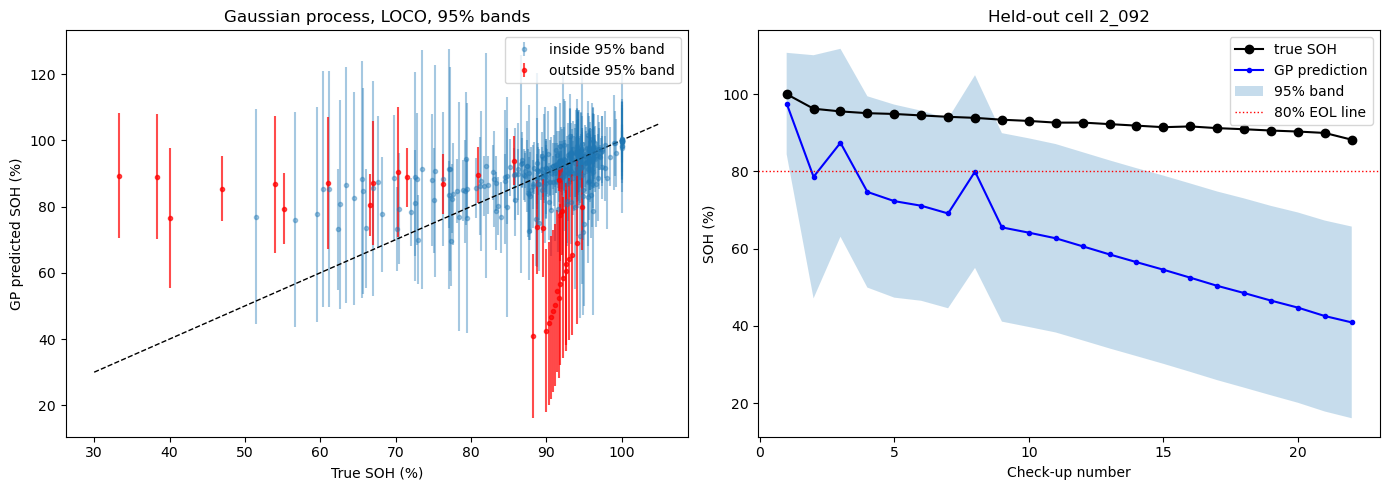

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Left: predicted vs true
ok = unc.inside_95.to_numpy()
ax[0].errorbar(y[ok], mu[ok], yerr=1.96 * sd[ok], fmt="o", ms=3, alpha=.4, label="inside 95% band")
ax[0].errorbar(y[~ok], mu[~ok], yerr=1.96 * sd[~ok], fmt="o", ms=3, color="red", alpha=.7, label="outside 95% band")
ax[0].plot([30, 105], [30, 105], "k--", lw=1)
ax[0].set(xlabel="True SOH (%)", ylabel="GP predicted SOH (%)", title="Gaussian process, LOCO, 95% bands")
ax[0].legend()

# Right: one held-out cell over time
cell = "2_092"
c = unc[unc.cell_id == cell].sort_values("rtp_index")
ax[1].plot(c.rtp_index, c.y_true, "ko-", label="true SOH")
ax[1].plot(c.rtp_index, c.y_pred, "b.-", label="GP prediction")
ax[1].fill_between(c.rtp_index, c.y_pred - 1.96 * c["std"], c.y_pred + 1.96 * c["std"], alpha=.25, label="95% band")
ax[1].axhline(80, color="red", ls=":", lw=1, label="80% EOL line")
ax[1].set(xlabel="Check-up number", ylabel="SOH (%)", title=f"Held-out cell {cell}")
ax[1].legend()

plt.tight_layout()
plt.savefig("gp_uncertainty.png", dpi=150)
plt.show()

## 6. Other splits: LOPO and random 5-fold
LOPO holds out a whole usage profile. The random split is shown only to measure how optimistic it is (generalization gap).

In [11]:
%%time
for scheme in ["LOPO", "Random 5-fold"]:
    for spec in [ridge, svr, gpr]:
        results.append(ev.run_cv(df, spec, scheme))

R = {(r.model, r.scheme): r for r in results}
display(ev.summary_table(results).round(2))
display(ev.generalization_gap(results).round(2))

Ridge | LOPO: fold 14
SVR (RBF) | LOPO: fold 14
Gaussian process | LOPO: fold 14
Ridge | Random 5-fold: fold 5
SVR (RBF) | Random 5-fold: fold 5
Gaussian process | Random 5-fold: fold 5


,model,scheme,n,MAE,RMSE,R2,MaxAE
0,Ridge,LOCO,306,4.76,7.63,0.53,49.88
1,SVR (RBF),LOCO,306,4.81,8.20,0.45,56.38
2,Gaussian process,LOCO,306,7.72,12.77,-0.32,56.06
3,Ridge,LOPO,306,4.89,7.72,0.52,51.49
4,SVR (RBF),LOPO,306,5.87,8.85,0.36,55.90
5,Gaussian process,LOPO,306,8.13,12.93,-0.36,56.06
6,Ridge,Random 5-fold,306,2.79,4.50,0.84,41.24
7,SVR (RBF),Random 5-fold,306,1.24,2.97,0.93,38.41
8,Gaussian process,Random 5-fold,306,1.30,2.88,0.93,35.18


scheme,LOCO,LOPO,Random 5-fold,gap LOCO - random,gap LOPO - random
model,,,,,
Gaussian process,7.72,8.13,1.30,6.42,6.83
Ridge,4.76,4.89,2.79,1.97,2.10
SVR (RBF),4.81,5.87,1.24,3.57,4.63


CPU times: user 1min 3s, sys: 12 s, total: 1min 15s
Wall time: 2min 22s


## 7. LOPO comparison and locked hold-out check (final model only)
The locked 3-cell check (2_009, 2_092, 2_098) is run only on the final model from this notebook, SVR, as the protocol requires. 

In [13]:
%%time
# 1) Is SVR vs Ridge consistent on LOPO too?
display(pd.DataFrame([
    ev.paired_comparison(R[("SVR (RBF)", "LOPO")],        R[("Ridge", "LOPO")]),
    ev.paired_comparison(R[("Gaussian process", "LOPO")], R[("Ridge", "LOPO")]),
]).round(3))

# 2) Locked hold-out: final model only (SVR)
holdout = pd.DataFrame([ev.holdout_check(df, svr)])
display(holdout.round(2))

,a,b,scheme,n_folds,mean_diff,a_wins,b_wins,wilcoxon_p
0,SVR (RBF),Ridge,LOPO,14,0.891,4,10,0.049
1,Gaussian process,Ridge,LOPO,14,3.346,3,11,0.013


,model,n_dev_cells,n_test,test_cells,MAE,RMSE
0,SVR (RBF),12,65,"2_009, 2_092, 2_098",6.19,9.67


CPU times: user 438 ms, sys: 70 ms, total: 508 ms
Wall time: 4.01 s


In [14]:
import os
out = ROOT / "results" / "nonlinear_svr_gpr"
os.makedirs(out, exist_ok=True)

ev.summary_table(results).to_csv(f"{out}/metrics_all_splits.csv", index=False)
ev.generalization_gap(results).to_csv(f"{out}/generalization_gap.csv")
pd.concat([r.folds for r in results]).to_csv(f"{out}/per_fold_metrics.csv", index=False)
pd.concat([r.oof for r in results]).to_csv(f"{out}/oof_predictions.csv", index=False)
pd.DataFrame([ev.paired_comparison(R[(a, s)], R[(b, s)])
              for s in ["LOCO", "LOPO"]
              for a, b in [("SVR (RBF)", "Ridge"), ("Gaussian process", "Ridge"),
                           ("Gaussian process", "SVR (RBF)")]]
            ).to_csv(f"{out}/paired_comparison.csv", index=False)
holdout.to_csv(f"{out}/holdout_check.csv", index=False)
unc.to_csv(f"{out}/gpr_uncertainty_loco.csv", index=False)
os.replace("gp_uncertainty.png", f"{out}/gp_uncertainty.png")

print(sorted(os.listdir(out)))

['generalization_gap.csv', 'gp_uncertainty.png', 'gpr_uncertainty_loco.csv', 'holdout_check.csv', 'metrics_all_splits.csv', 'oof_predictions.csv', 'paired_comparison.csv', 'per_fold_metrics.csv']


## 8. Summary
| Model | LOCO | LOPO | Random 5-fold |
|---|---|---|---|
| Ridge | 4.76 | 4.89 | 2.79 |
| SVR (RBF) | 4.81 | 5.87 | 1.24 |
| Gaussian process | 7.72 | 8.13 | 1.30 |

- **SVR does not beat Ridge.** On LOCO they are about the same (p = 0.85). On LOPO SVR is worse (10 of 14 folds, p = 0.049).
- **The Gaussian process is the weakest model** (worse than Ridge and SVR, p < 0.05), but its uncertainty is useful: a bigger std goes with a bigger error (corr = 0.60). The 95% band covers 97% of interpolation rows but only 67% of extrapolation rows, so it is over-confident on unfamiliar batteries (e.g. cell 2_092).
- **The random split is far too optimistic**, especially for the non-linear models (gap: Ridge ≈ 2, SVR ≈ 3.6–4.6, GP ≈ 6.4–6.8).
- **All models overestimate SOH for batteries near end of life** (bias +9 to +16 points). The largest errors (≈ 56) come from cell 2_095, which drops to 33–38% SOH.
- **Locked hold-out (final model only, SVR):** MAE 6.19 on cells 2_009, 2_092, 2_098.
- **Conclusion:** non-linear models do not improve on Ridge here; Ridge stays the simpler and equally good choice.